# Cell 1: The Cropper (Builds the data locally)

In [1]:
# import os
# import cv2
# from tqdm import tqdm

# print("Hunting for the mounted dataset in Kaggle inputs...")
# INPUT_DATASET_PATH = None

# for root, dirs, files in os.walk('/kaggle/input'):
#     if 'tfp_dataset' in dirs:
#         INPUT_DATASET_PATH = os.path.join(root, 'tfp_dataset')
#         break 

# if not INPUT_DATASET_PATH:
#     raise ValueError("CRITICAL ERROR: Could not find 'tfp_dataset'. Did you click 'Add Input' to mount your dataset?")

# CNN_DATA = "/kaggle/working/cnn_dataset"
# CLASSES = ["Car", "Bus", "Truck", "Motorcycle", "Bicycle", "Rickshaw", "Mini-Truck", "CNG", "Pedestrian"]

# print("Building Image Classification Directories...")
# for split in ['train', 'val', 'test']:
#     for cls in CLASSES:
#         os.makedirs(os.path.join(CNN_DATA, split, cls), exist_ok=True)

# def crop_yolo_boxes(split):
#     images_dir = os.path.join(INPUT_DATASET_PATH, split, 'images')
#     labels_dir = os.path.join(INPUT_DATASET_PATH, split, 'labels')
    
#     if not os.path.exists(images_dir): return
    
#     image_files = [f for f in os.listdir(images_dir) if f.endswith(('.jpg', '.png'))]
#     print(f"\nCropping {split} street scenes into individual objects...")

#     for img_file in tqdm(image_files):
#         img_path = os.path.join(images_dir, img_file)
#         txt_file = img_file.rsplit('.', 1)[0] + '.txt'
#         txt_path = os.path.join(labels_dir, txt_file)
        
#         if not os.path.exists(txt_path): continue
            
#         img = cv2.imread(img_path)
#         if img is None: continue
#         h, w, _ = img.shape
        
#         with open(txt_path, 'r') as f:
#             lines = f.readlines()
            
#         for idx, line in enumerate(lines):
#             parts = line.strip().split()
#             if len(parts) != 5: continue
                
#             class_id = int(parts[0])
#             x_center, y_center, box_w, box_h = map(float, parts[1:])
            
#             x1 = max(0, int((x_center - box_w/2) * w))
#             y1 = max(0, int((y_center - box_h/2) * h))
#             x2 = min(w, int((x_center + box_w/2) * w))
#             y2 = min(h, int((y_center + box_h/2) * h))
            
#             if x2 - x1 < 15 or y2 - y1 < 15: continue 
                
#             crop = img[y1:y2, x1:x2]
#             class_name = CLASSES[class_id]
#             save_path = os.path.join(CNN_DATA, split, class_name, f"{img_file.split('.')[0]}_{idx}.jpg")
#             cv2.imwrite(save_path, crop)

# crop_yolo_boxes('train')
# crop_yolo_boxes('val')
# print("\nSuccess! Dataset is reformatted and ready for MobileNetV3.")

# Cell 2: MobileNetV3 Training (With RAM Saver)

In [2]:
# import tensorflow as tf
# from tensorflow.keras.preprocessing.image import ImageDataGenerator
# from tensorflow.keras.applications import MobileNetV3Large
# from tensorflow.keras.models import Model
# from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
# from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, Callback

# # RAM Protection: Lower batch size prevents silent Kaggle crashes
# IMG_SIZE = 224 
# BATCH_SIZE = 16
# CNN_DATA = "/kaggle/working/cnn_dataset"

# print("Setting up Data Generators...")
# train_datagen = ImageDataGenerator(rescale=1./255, rotation_range=15, horizontal_flip=True, brightness_range=[0.8, 1.2])
# val_datagen = ImageDataGenerator(rescale=1./255)

# train_generator = train_datagen.flow_from_directory(f'{CNN_DATA}/train', target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, class_mode='categorical')
# val_generator = val_datagen.flow_from_directory(f'{CNN_DATA}/val', target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, class_mode='categorical')

# # Checkpoint Saver: Saves your model every 5 epochs
# class SaveEveryFiveEpochsMobile(Callback):
#     def on_epoch_end(self, epoch, logs=None):
#         if (epoch + 1) % 5 == 0:
#             save_path = f'/kaggle/working/mobilenetv3_epoch_{epoch+1}.keras'
#             self.model.save(save_path)
#             print(f"\n[INFO] Checkpoint securely saved at Epoch {epoch+1}")

# print("Building MobileNetV3-Large Architecture...")
# base_model_mobile = MobileNetV3Large(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
# for layer in base_model_mobile.layers: layer.trainable = False

# y = base_model_mobile.output
# y = GlobalAveragePooling2D()(y)
# y = Dense(512, activation='relu')(y)
# predictions_mobile = Dense(9, activation='softmax')(y)

# model_mobilenet = Model(inputs=base_model_mobile.input, outputs=predictions_mobile)
# model_mobilenet.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# checkpoint_best = ModelCheckpoint('/kaggle/working/best_mobilenetv3.keras', monitor='val_accuracy', save_best_only=True, verbose=1)
# early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# print("Starting MobileNetV3 Training (15 Epochs Maximum)...")
# history_mobile = model_mobilenet.fit(
#     train_generator, 
#     validation_data=val_generator, 
#     epochs=15, 
#     callbacks=[checkpoint_best, early_stop, SaveEveryFiveEpochsMobile()]
# )

# Cell 3: MobileNet Visuals

In [3]:
# import matplotlib.pyplot as plt

# def plot_training_history(history_obj, model_name):
#     plt.figure(figsize=(14, 5))
#     plt.subplot(1, 2, 1)
#     plt.plot(history_obj.history['accuracy'], label='Train Acc', color='blue', linewidth=2)
#     plt.plot(history_obj.history['val_accuracy'], label='Val Acc', color='orange', linestyle='--', linewidth=2)
#     plt.title(f'{model_name}: Accuracy', fontweight='bold')
#     plt.legend()
#     plt.grid(True, linestyle=':', alpha=0.7)
    
#     plt.subplot(1, 2, 2)
#     plt.plot(history_obj.history['loss'], label='Train Loss', color='red', linewidth=2)
#     plt.plot(history_obj.history['val_loss'], label='Val Loss', color='green', linestyle='--', linewidth=2)
#     plt.title(f'{model_name}: Loss', fontweight='bold')
#     plt.legend()
#     plt.grid(True, linestyle=':', alpha=0.7)
    
#     plt.savefig(f'/kaggle/working/{model_name}_curves.png')
#     plt.show()

# if 'history_mobile' in locals(): 
#     plot_training_history(history_mobile, 'MobileNetV3')

Loading the best saved model...


I0000 00:00:1793561531.787350      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793561531.791306      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Setting up validation data...
Found 30720 images belonging to 9 classes.
Running inference on the validation set...


2026-11-01 19:32:29.425624: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-01 19:32:29.560377: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-01 19:32:29.892556: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-01 19:32:30.028945: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1793561552.649471      69 device_compiler.h:196]

1920/1920 ━━━━━━━━━━━━━━━━━━━━ 3381s 2s/step

--- Classification Report ---
              precision    recall  f1-score   support

     Bicycle       0.00      0.00      0.00       127
         Bus       0.74      0.71      0.72      6695
         CNG       0.63      0.46      0.53      3579
         Car       0.70      0.75      0.73      6384
  Mini-Truck       0.37      0.15      0.21      1060
  Motorcycle       0.68      0.63      0.65      2324
  Pedestrian       0.62      0.85      0.72      3525
    Rickshaw       0.70      0.75      0.72      6759
       Truck       0.16      0.02      0.03       267

    accuracy                           0.68     30720
   macro avg       0.51      0.48      0.48     30720
weighted avg       0.67      0.68      0.67     30720

Generating Confusion Matrix...


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


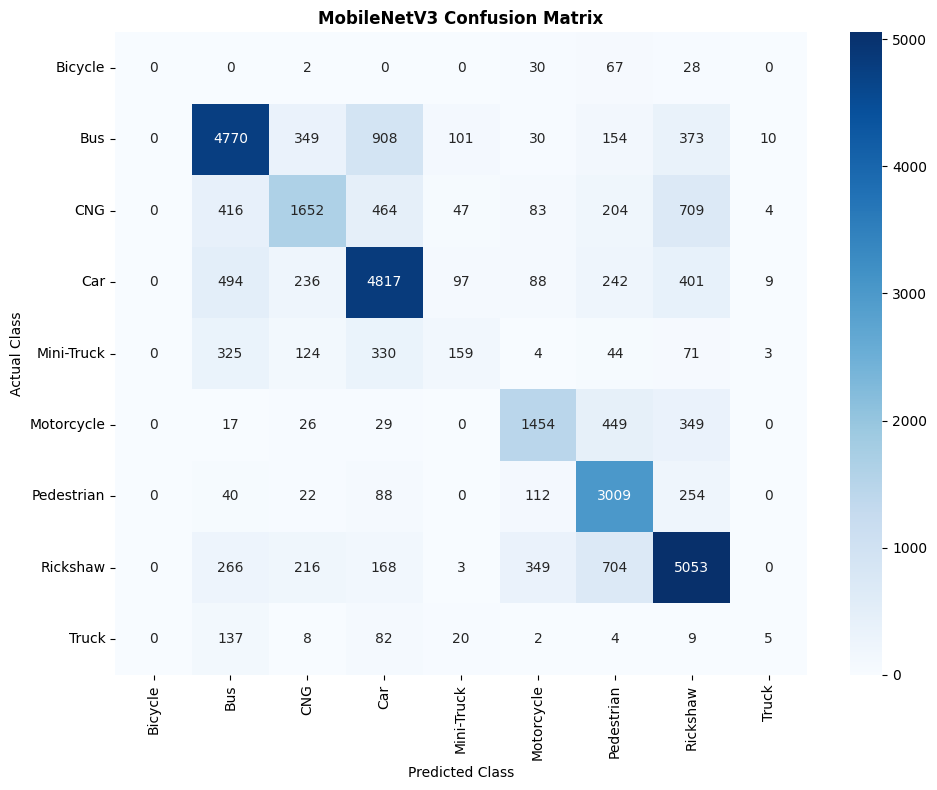

In [4]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 1. Update this to match the name of your attached notebook!
INPUT_DIR = "/kaggle/input/notebooks/sharminaktermukta/mobilenetv3-model-trainning" 

IMG_SIZE = 224 
BATCH_SIZE = 16
CNN_DATA = f"{INPUT_DIR}/cnn_dataset"

# 2. Load the model directly from the attached input
print("Loading the best saved model...")
saved_model = load_model(f'{INPUT_DIR}/best_mobilenetv3.keras')

# 3. Create the un-shuffled validation generator
print("Setting up validation data...")
val_datagen = ImageDataGenerator(rescale=1./255)
eval_generator = val_datagen.flow_from_directory(
    f'{CNN_DATA}/val', 
    target_size=(IMG_SIZE, IMG_SIZE), 
    batch_size=BATCH_SIZE, 
    class_mode='categorical',
    shuffle=False
)

# 4. Run inference and generate metrics
print("Running inference on the validation set...")
# Added int() to fix the float64 error
predictions = saved_model.predict(eval_generator, steps=int(np.ceil(eval_generator.samples / BATCH_SIZE)))
predicted_classes = np.argmax(predictions, axis=1)

true_classes = eval_generator.classes
class_labels = list(eval_generator.class_indices.keys())

print("\n--- Classification Report ---")
print(classification_report(true_classes, predicted_classes, target_names=class_labels))

print("Generating Confusion Matrix...")
cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('MobileNetV3 Confusion Matrix', fontweight='bold')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.tight_layout()
plt.savefig('/kaggle/working/saved_model_confusion_matrix.png')
plt.show()